# 05 — Evaluation

Notebook ini menjalankan tahap **Evaluation** CRISP-DM untuk klasifikasi biner audio:

- `1 = berisik`
- `0 = non-berisik`

Tujuan tahap ini adalah menguji **satu kali** model yang sudah tersimpan pada **NIM hold-out yang dikunci di Tahap 04**, melaporkan metrik aktual beserta ketidakpastiannya, dan menilai syarat kelayakan awal ROC-AUC ≥ 0,85 apa adanya. Tidak ada pelatihan, penalaan, atau pemilihan model di tahap ini.

## Masukan

- `artifacts/best_model.joblib`: pipeline terpilih dari Tahap 04.
- `artifacts/04_modeling/model_config.json` dan `validation_summary.json`.
- `artifacts/04_modeling/holdout_file_split.csv`: pembagian NIM train/test terkunci.
- `artifacts/features.csv`: 176 baris fitur Tahap 03 (dipakai hanya untuk baris NIM test).

## Keluaran utama

- `artifacts/test_results/test_predictions.csv`: prediksi per file uji.
- `artifacts/test_results/metrics.json`: ROC-AUC, PR-AUC, accuracy, precision, recall, F1, confusion matrix, confidence interval bootstrap, dan status syarat 0,85.
- `artifacts/test_results/classification_report.csv`, `confusion_matrix.csv`, `metrics_by_nim.csv`, `errors.csv`.
- `artifacts/test_results/figures/`: kurva ROC, kurva PR, confusion matrix, distribusi probabilitas, dan distribusi bootstrap ROC-AUC.
- `artifacts/05_evaluation/`: laporan dan validasi tahap.

## Batasan yang dipegang

1. Evaluasi hanya memakai **7 NIM test / 40 file**; NIM train tidak pernah muncul di metrik.
2. Model **tidak** di-fit ulang, tidak ada threshold baru, dan tidak ada pemilihan fitur di tahap ini.
3. Threshold keputusan tetap 0,50 sesuai pipeline, bukan hasil penalaan pada data uji.
4. Syarat ROC-AUC ≥ 0,85 adalah syarat kelayakan awal; hasil di bawahnya dilaporkan apa adanya.
5. Semua angka berasal dari eksekusi nyata; `raw_audio/` tidak diubah.


In [1]:
import hashlib
import json
import pickle
import platform
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found.*")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42

library_versions = pd.DataFrame(
    {
        "komponen": [
            "Python",
            "numpy",
            "pandas",
            "scikit-learn",
            "joblib",
            "matplotlib",
            "seaborn",
        ],
        "versi": [
            platform.python_version(),
            np.__version__,
            pd.__version__,
            __import__("sklearn").__version__,
            joblib.__version__,
            plt.matplotlib.__version__,
            sns.__version__,
        ],
    }
)

display(library_versions)


,komponen,versi
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,2.3.3
3,scikit-learn,1.8.0
4,joblib,1.5.3
5,matplotlib,3.11.0
6,seaborn,0.13.2


In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "raw_audio").is_dir() and (candidate / "artifacts").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder proyek dengan raw_audio/ dan artifacts/ tidak ditemukan.")

ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR = ARTIFACT_ROOT / "05_evaluation"
FIGURE_DIR = ARTIFACT_DIR / "figures"
TEST_RESULTS_DIR = ARTIFACT_ROOT / "test_results"
TEST_FIGURE_DIR = TEST_RESULTS_DIR / "figures"

FEATURES_PATH = ARTIFACT_ROOT / "features.csv"
MODEL_PATH = ARTIFACT_ROOT / "best_model.joblib"
MODEL_CONFIG_PATH = ARTIFACT_ROOT / "04_modeling" / "model_config.json"
STAGE4_VALIDATION_PATH = ARTIFACT_ROOT / "04_modeling" / "validation_summary.json"
HOLDOUT_FILE_PATH = ARTIFACT_ROOT / "04_modeling" / "holdout_file_split.csv"

PREDICTIONS_PATH = TEST_RESULTS_DIR / "test_predictions.csv"
METRICS_PATH = TEST_RESULTS_DIR / "metrics.json"
REPORT_METRICS_PATH = TEST_RESULTS_DIR / "classification_report.csv"
CONFUSION_PATH = TEST_RESULTS_DIR / "confusion_matrix.csv"
METRICS_BY_NIM_PATH = TEST_RESULTS_DIR / "metrics_by_nim.csv"
ERRORS_PATH = TEST_RESULTS_DIR / "errors.csv"

for directory in [ARTIFACT_DIR, FIGURE_DIR, TEST_RESULTS_DIR, TEST_FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

IDENTITY_COLUMNS = ["file", "nim", "take", "label"]

FEATURE_COLUMNS = [
    "mse_energy",
    "rms_mean",
    "rms_std",
    "rms_max",
    "rms_min",
    "zcr_mean",
    "zcr_std",
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_flatness_mean",
    "spectral_rolloff_mean",
    "spectral_bandwidth_mean",
]

LABEL_NAME_MAP = {0: "non-berisik", 1: "berisik"}

TEST_THRESHOLD = 0.5
ROC_AUC_THRESHOLD = 0.85
BASELINE_ROC_AUC = 0.5
BOOTSTRAP_N = 2000
RANDOM_STATE = 42

FIGURES_EXPECTED = [
    "roc_curve.png",
    "pr_curve.png",
    "confusion_matrix.png",
    "proba_distribution.png",
    "roc_auc_bootstrap.png",
]

CONFIG = pd.DataFrame(
    {
        "parameter": [
            "project_root",
            "model",
            "threshold keputusan",
            "syarat kelayakan ROC-AUC",
            "baseline ROC-AUC",
            "jumlah bootstrap",
            "output evaluasi",
            "random_state",
        ],
        "nilai": [
            str(PROJECT_ROOT),
            str(MODEL_PATH),
            TEST_THRESHOLD,
            ROC_AUC_THRESHOLD,
            BASELINE_ROC_AUC,
            BOOTSTRAP_N,
            str(TEST_RESULTS_DIR),
            RANDOM_STATE,
        ],
    }
)

display(CONFIG)


,parameter,nilai
0,project_root,C:\Users\ASUS\Downloads\dataset_30_detik
1,model,C:\Users\ASUS\Downloads\dataset_30_detik\artif...
2,threshold keputusan,0.5
3,syarat kelayakan ROC-AUC,0.85
4,baseline ROC-AUC,0.5
5,jumlah bootstrap,2000
6,output evaluasi,C:\Users\ASUS\Downloads\dataset_30_detik\artif...
7,random_state,42


## 1. Pintu masuk: model dan pembagian dari Tahap 04

Section ini memuat artefak Tahap 04 tanpa menyentuhnya dan mengunci siapa yang berhak diuji.

Syarat yang diverifikasi:

1. `validation_summary.json` Tahap 04 berstatus **PASS** dengan seluruh pemeriksaan lulus dan `holdout_tested_in_stage_04 = false`.
2. `best_model.joblib` ada, berisi pipeline `scaler -> select -> clf`, dan konfigurasinya cocok dengan daftar fitur yang dipakai.
3. `holdout_file_split.csv` menetapkan 40 file pada **split test** yang seluruhnya berasal dari 7 NIM test; tidak ada file train yang ikut.
4. Sidik jari model dicatat saat dimuat dan dicek ulang di validasi akhir, sehingga terbukti model tidak di-fit ulang di tahap ini.

Bila satu saja syarat gagal, evaluasi berhenti.


In [3]:
stage4_validation = json.loads(STAGE4_VALIDATION_PATH.read_text(encoding="utf-8"))
assert stage4_validation["status"] == "PASS", "Validasi Tahap 04 berstatus bukan PASS."
assert (
    stage4_validation["checks_passed"] == stage4_validation["checks_total"]
), "Terdapat pemeriksaan Tahap 04 yang gagal."
assert stage4_validation["holdout_tested_in_stage_04"] is False, (
    "Hold-out sudah pernah diuji pada Tahap 04; evaluasi menjadi tidak independen."
)

assert MODEL_PATH.is_file(), "best_model.joblib tidak ditemukan."
model_config = json.loads(MODEL_CONFIG_PATH.read_text(encoding="utf-8"))
saved_model = joblib.load(MODEL_PATH)

assert list(saved_model.named_steps) == ["scaler", "select", "clf"], (
    f"Struktur pipeline berubah: {list(saved_model.named_steps)}"
)
assert model_config["model_name"] == "Logistic Regression"
assert model_config["feature_columns"] == FEATURE_COLUMNS, "Daftar fitur config tidak cocok."
assert int(model_config["train_rows"]) == 136, "Jumlah file train Tahap 04 berubah."
assert int(saved_model.n_features_in_) == len(FEATURE_COLUMNS)

model_fingerprint_at_load = hashlib.sha256(pickle.dumps(saved_model)).hexdigest()
model_file_sha256_at_load = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

features = pd.read_csv(FEATURES_PATH)
features["label"] = features["label"].astype(int)
features["take"] = features["take"].astype(int)
features["label_name"] = features["label"].map(LABEL_NAME_MAP)
assert len(features) == 176, f"features.csv berisi {len(features)} baris."
assert np.isfinite(features[FEATURE_COLUMNS].to_numpy(dtype=float)).all(), "Fitur mengandung NaN/Inf."

holdout_file_split = pd.read_csv(HOLDOUT_FILE_PATH)
assert len(holdout_file_split) == 176, "holdout_file_split.csv tidak berisi 176 baris."
assert set(holdout_file_split["split"]) == {"train", "test"}, "Nilai split tidak sesuai."

nims_train = sorted(model_config["holdout"]["nims_train"])
nims_test = sorted(model_config["holdout"]["nims_test"])
assert len(nims_test) == 7 and len(nims_train) == 27, "Jumlah NIM train/test berubah."
assert set(nims_train).isdisjoint(set(nims_test)), "NIM train dan test beririsan."

test_files = holdout_file_split.loc[holdout_file_split["split"] == "test"]
assert len(test_files) == 40, f"File test berjumlah {len(test_files)}, bukan 40."
assert sorted(test_files["nim"].unique()) == nims_test, "NIM test tidak cocok dengan config."

merged = features.merge(
    holdout_file_split[["file", "split"]],
    on="file",
    how="inner",
    validate="one_to_one",
)
assert len(merged) == 176, "Gabungan features dan holdout tidak 176 baris."

test_frame = merged.loc[merged["split"] == "test"].reset_index(drop=True)
train_frame = merged.loc[merged["split"] == "train"].reset_index(drop=True)
assert len(test_frame) == 40 and len(train_frame) == 136
assert sorted(test_frame["nim"].unique()) == nims_test
assert set(test_frame["nim"]).isdisjoint(set(nims_train)), "Data uji mengandung NIM train."
assert (
    int((test_frame["label"] == 0).sum()) == 21 and int((test_frame["label"] == 1).sum()) == 19
), "Komposisi kelas data uji berubah."

gate_summary = pd.DataFrame(
    {
        "pemeriksaan": [
            "status validasi Tahap 04",
            "hold-out belum diuji di Tahap 04",
            "model dimuat",
            "sidik jari model",
            "file uji (NIM test)",
            "file latih (NIM train)",
            "NIM test",
            "kelas uji (0 : 1)",
        ],
        "nilai": [
            stage4_validation["status"],
            stage4_validation["holdout_tested_in_stage_04"],
            model_config["model_name"],
            model_fingerprint_at_load[:16],
            len(test_frame),
            len(train_frame),
            len(nims_test),
            f"{int((test_frame['label'] == 0).sum())} : {int((test_frame['label'] == 1).sum())}",
        ],
    }
)
display(gate_summary)
print("Pintu masuk Tahap 05: LULUS")


,pemeriksaan,nilai
0,status validasi Tahap 04,PASS
1,hold-out belum diuji di Tahap 04,False
2,model dimuat,Logistic Regression
3,sidik jari model,cbbb5b163e986125
4,file uji (NIM test),40
5,file latih (NIM train),136
6,NIM test,7
7,kelas uji (0 : 1),21 : 19


Pintu masuk Tahap 05: LULUS


## 2. Prediksi pada NIM test

Model yang dimuat langsung dipakai untuk memprediksi 40 file uji:

1. `predict_proba` menghasilkan probabilitas kelas 0 dan 1; label prediksi ditentukan dengan **threshold 0,50** yang sama dengan aturan `predict` dua kelas dan tidak dituning pada data uji.
2. Hasil per file disimpan di `test_predictions.csv` berisi probabilitas kedua kelas, label prediksi, label sebenarnya, dan penanda benar/salah.
3. Tidak ada langkah preprocessing tambahan: fitur berasal dari `features.csv` yang dihasilkan prosedur identik dengan deployment.
4. Threshold, pipeline, dan fitur persis seperti yang dipakai Tahap 04; tidak ada yang disesuaikan setelah melihat data uji.


In [4]:
X_test = test_frame[FEATURE_COLUMNS].to_numpy(dtype=float)
y_test = test_frame["label"].to_numpy(dtype=int)

assert np.isfinite(X_test).all(), "Fitur uji mengandung NaN/Inf."
assert X_test.shape == (40, len(FEATURE_COLUMNS))

class_index_1 = int(np.where(saved_model.classes_ == 1)[0][0])
proba = saved_model.predict_proba(X_test)
assert proba.shape == (40, 2), f"Bentuk probabilitas {proba.shape} tidak sesuai."
assert np.allclose(proba.sum(axis=1), 1.0), "Probabilitas per baris tidak berjumlah 1."

proba_1 = proba[:, class_index_1]
proba_0 = proba[:, 1 - class_index_1]
pred_label = (proba_1 >= TEST_THRESHOLD).astype(int)
pred_from_model = saved_model.predict(X_test)
assert np.array_equal(pred_label, pred_from_model), (
    "Threshold 0,50 tidak konsisten dengan predict() pipeline."
)

test_predictions = test_frame[
    ["file", "nim", "take", "label", "label_name", "split"]
].copy()
test_predictions["proba_non_berisik"] = proba_0
test_predictions["proba_berisik"] = proba_1
test_predictions["pred_label"] = pred_label
test_predictions["pred_label_name"] = pd.Series(pred_label).map(LABEL_NAME_MAP).values
test_predictions["proba_diprediksi"] = np.maximum(proba_0, proba_1)
test_predictions["benar"] = pred_label == y_test

assert not test_predictions[["proba_non_berisik", "proba_berisik"]].isna().any().any()
assert set(test_predictions["nim"]).issubset(set(nims_test))
assert len(test_predictions) == 40 and test_predictions["file"].is_unique

test_predictions = test_predictions.sort_values("nim").reset_index(drop=True)
test_predictions.to_csv(PREDICTIONS_PATH, index=False)

prediction_summary = pd.DataFrame(
    {
        "baris": ["semua", "aktual_0", "aktual_1", "diprediksi_0", "diprediksi_1", "benar"],
        "jumlah": [
            len(test_predictions),
            int((y_test == 0).sum()),
            int((y_test == 1).sum()),
            int((pred_label == 0).sum()),
            int((pred_label == 1).sum()),
            int((pred_label == y_test).sum()),
        ],
    }
)
display(prediction_summary)
display(test_predictions.head(10).round(4))
print(f"Prediksi disimpan: {PREDICTIONS_PATH}")


,baris,jumlah
0,semua,40
1,aktual_0,21
2,aktual_1,19
3,diprediksi_0,20
4,diprediksi_1,20
5,benar,31


,file,nim,take,label,label_name,split,proba_non_berisik,proba_berisik,pred_label,pred_label_name,proba_diprediksi,benar
0,24-068_non-berisik_1.wav,24-068,1,0,non-berisik,test,0.2643,0.7357,1,berisik,0.7357,False
1,24-068_non-berisik_2.wav,24-068,2,0,non-berisik,test,0.4475,0.5525,1,berisik,0.5525,False
2,24-068_non-berisik_3.wav,24-068,3,0,non-berisik,test,0.6811,0.3189,0,non-berisik,0.6811,True
3,24-068_berisik_1.wav,24-068,1,1,berisik,test,0.0894,0.9106,1,berisik,0.9106,True
4,24-068_berisik_2.wav,24-068,2,1,berisik,test,0.1503,0.8497,1,berisik,0.8497,True
5,24-068_berisik_3.wav,24-068,3,1,berisik,test,0.1583,0.8417,1,berisik,0.8417,True
6,24-100_berisik_3.wav,24-100,3,1,berisik,test,0.0417,0.9583,1,berisik,0.9583,True
7,24-100_berisik_1.wav,24-100,1,1,berisik,test,0.1533,0.8467,1,berisik,0.8467,True
8,24-100_berisik_2.wav,24-100,2,1,berisik,test,0.0955,0.9045,1,berisik,0.9045,True
9,24-100_non-berisik_2.wav,24-100,2,0,non-berisik,test,0.8452,0.1548,0,non-berisik,0.8452,True


Prediksi disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\test_results\test_predictions.csv


## 3. Metrik hold-out

Metrik dihitung dari 40 file uji saja:

| Metrik | Peran |
|---|---|
| ROC-AUC | Kemampuan memberi skor berisik lebih tinggi; dibandingkan dengan baseline 0,50 dan syarat kelayakan 0,85 |
| PR-AUC (average precision) | Pemeringkatan kelas berisik dengan baseline = prevalensi kelas berisik pada data uji |
| Precision, recall, F1 kelas 1 | Kualitas penandaan berisik pada ambang 0,50 |
| Accuracy | Pelengkap; dibaca bersama confusion matrix |
| Confusion matrix | Jumlah TN, FP, FN, TP secara langsung |
| Classification report | Metrik per kelas lengkap dengan support |

Status syarat kelayakan (`ROC-AUC ≥ 0,85`) dihitung dari angka nyata; bila tidak terpenuhi, hasil tetap dilaporkan sebagai **di bawah syarat awal**, tidak disesuaikan.


In [5]:
roc_auc_value = float(roc_auc_score(y_test, proba_1))
pr_auc_value = float(average_precision_score(y_test, proba_1))
accuracy_value = float(accuracy_score(y_test, pred_label))
precision_value = float(precision_score(y_test, pred_label, zero_division=0))
recall_value = float(recall_score(y_test, pred_label, zero_division=0))
f1_value = float(f1_score(y_test, pred_label, zero_division=0))

cm_array = confusion_matrix(y_test, pred_label, labels=[0, 1])
tn, fp, fn, tp = (int(value) for value in cm_array.ravel())
assert tn + fp + fn + tp == len(y_test), "Confusion matrix tidak berjumlah 40."

report_dict = classification_report(
    y_test,
    pred_label,
    labels=[0, 1],
    target_names=["non-berisik", "berisik"],
    output_dict=True,
    zero_division=0,
)
report_frame = pd.DataFrame(report_dict).T.round(4)
report_frame.index.name = "kelas"
report_frame.to_csv(REPORT_METRICS_PATH)

cm_frame = pd.DataFrame(
    cm_array, index=["actual_non_berisik", "actual_berisik"], columns=["pred_non_berisik", "pred_berisik"]
)
cm_frame.to_csv(CONFUSION_PATH)

prevalence_value = float(y_test.mean())
meets_kelayakan = bool(roc_auc_value >= ROC_AUC_THRESHOLD)

metrics = {
    "stage": "05_evaluation",
    "model_name": model_config["model_name"],
    "model_class": model_config["model_class"],
    "model_file": str(MODEL_PATH.relative_to(PROJECT_ROOT)),
    "n_files_test": int(len(y_test)),
    "n_nim_test": int(len(nims_test)),
    "nims_test": nims_test,
    "class_counts_test": {
        "0": int((y_test == 0).sum()),
        "1": int((y_test == 1).sum()),
    },
    "test_threshold": TEST_THRESHOLD,
    "roc_auc": roc_auc_value,
    "pr_auc": pr_auc_value,
    "accuracy": accuracy_value,
    "precision_class_1": precision_value,
    "recall_class_1": recall_value,
    "f1_class_1": f1_value,
    "confusion_matrix": {"tn": tn, "fp": fp, "fn": fn, "tp": tp},
    "baseline_roc_auc": BASELINE_ROC_AUC,
    "pr_baseline_prevalence": prevalence_value,
    "roc_auc_threshold": ROC_AUC_THRESHOLD,
    "roc_auc_meets_threshold": meets_kelayakan,
    "kelayakan_status": (
        "LOLOS SYARAT AWAL" if meets_kelayakan else "DI BAWAH SYARAT AWAL"
    ),
    "best_cv_roc_auc_tahap_04": float(model_config["best_cv_roc_auc"]),
    "random_state": RANDOM_STATE,
}
METRICS_PATH.write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

metrics_table = pd.DataFrame(
    {
        "metrik": [
            "ROC-AUC",
            "PR-AUC",
            "accuracy",
            "precision (kelas 1)",
            "recall (kelas 1)",
            "F1 (kelas 1)",
            "confusion TN / FP / FN / TP",
            "baseline ROC-AUC",
            "baseline PR (prevalensi)",
            "syarat kelayakan ROC-AUC",
            "status syarat",
        ],
        "nilai": [
            f"{roc_auc_value:.4f}",
            f"{pr_auc_value:.4f}",
            f"{accuracy_value:.4f}",
            f"{precision_value:.4f}",
            f"{recall_value:.4f}",
            f"{f1_value:.4f}",
            f"{tn} / {fp} / {fn} / {tp}",
            f"{BASELINE_ROC_AUC:.4f}",
            f"{prevalence_value:.4f}",
            f"{ROC_AUC_THRESHOLD:.2f}",
            metrics["kelayakan_status"],
        ],
    }
)
display(metrics_table)
display(report_frame)
display(cm_frame)
print(f"Metrik disimpan: {METRICS_PATH}")


,metrik,nilai
0,ROC-AUC,0.8296
1,PR-AUC,0.8481
2,accuracy,0.7750
3,precision (kelas 1),0.7500
4,recall (kelas 1),0.7895
5,F1 (kelas 1),0.7692
6,confusion TN / FP / FN / TP,16 / 5 / 4 / 15
7,baseline ROC-AUC,0.5000
8,baseline PR (prevalensi),0.4750
9,syarat kelayakan ROC-AUC,0.85


,precision,recall,f1-score,support
kelas,,,,
non-berisik,0.8000,0.7619,0.7805,21.000
berisik,0.7500,0.7895,0.7692,19.000
accuracy,0.7750,0.7750,0.7750,0.775
macro avg,0.7750,0.7757,0.7749,40.000
weighted avg,0.7762,0.7750,0.7751,40.000


,pred_non_berisik,pred_berisik
actual_non_berisik,16,5
actual_berisik,4,15


Metrik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\test_results\metrics.json


## 4. Kurva dan matriks

Empat gambar ditulis ke `artifacts/test_results/figures/`:

1. **Kurva ROC** — TPR vs FPR dengan luas kurva (ROC-AUC) dan diagonal acak 0,50 sebagai acuan.
2. **Kurva PR** — precision vs recall untuk kelas berisik; garis datar = prevalensi kelas berisik pada data uji, yaitu baseline PR yang jujur.
3. **Confusion matrix** — heatmap TN/FP/FN/TP dengan angka sel di dalam sel.
4. **Distribusi probabilitas** — histogram `proba(berisik)` untuk file berisik dan non-berisik, dengan garis threshold 0,50; gambar ini menunjukkan seberapa tumpang tindih kedua kelas.

Semua gambar dihasilkan dari 40 file uji yang sama dengan tabel metrik.


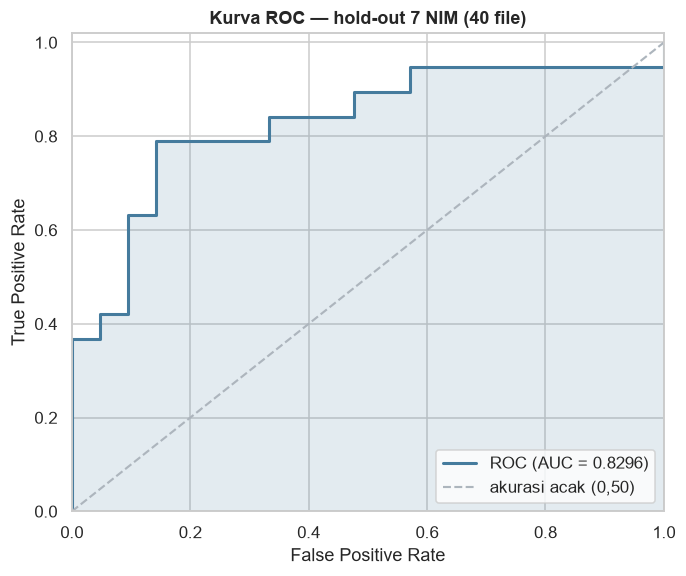

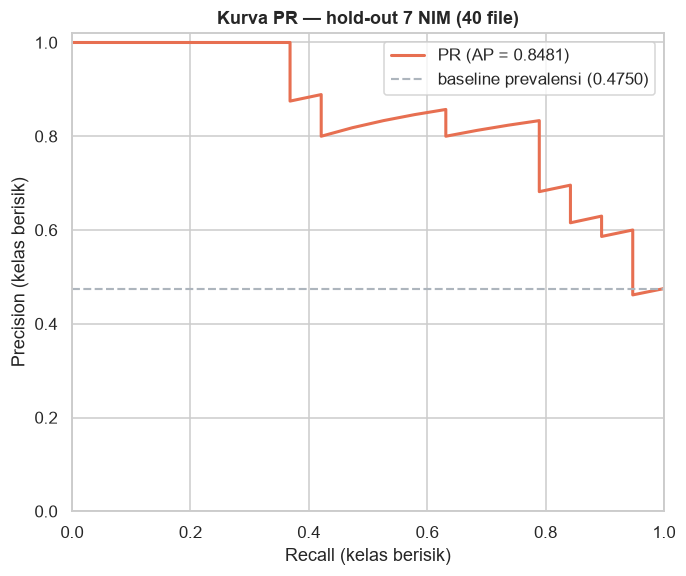

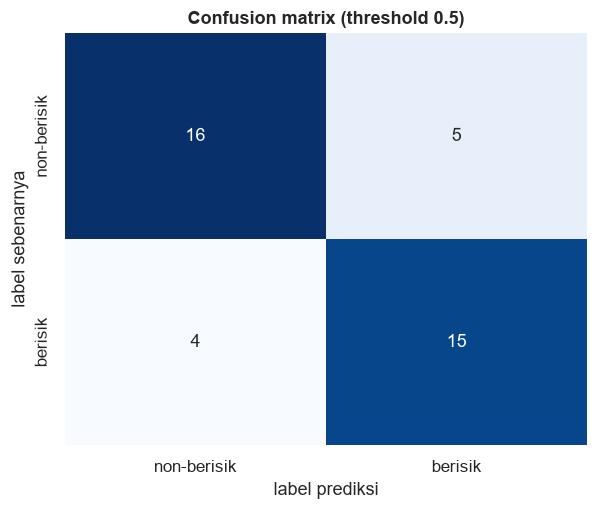

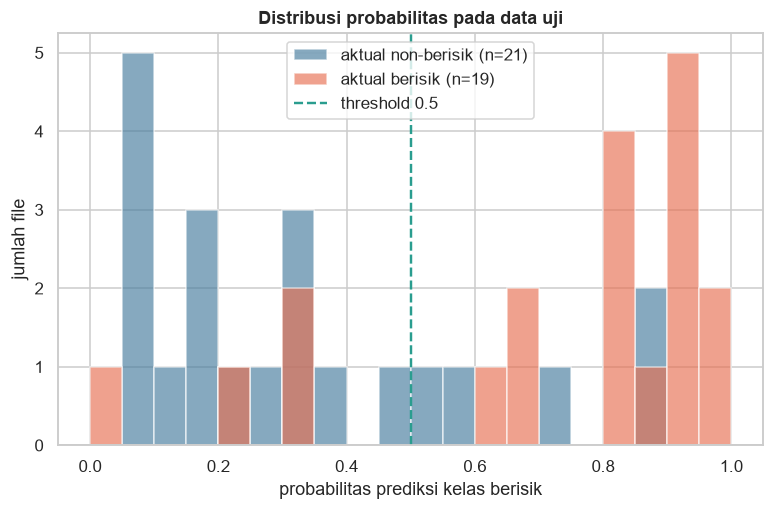

Gambar evaluasi: roc_curve.png, pr_curve.png, confusion_matrix.png, proba_distribution.png


In [6]:
fpr, tpr, roc_thresholds = roc_curve(y_test, proba_1)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.plot(fpr, tpr, color="#457b9d", linewidth=2, label=f"ROC (AUC = {roc_auc_value:.4f})")
ax.plot([0, 1], [0, 1], color="#adb5bd", linestyle="--", linewidth=1.4, label="akurasi acak (0,50)")
ax.fill_between(fpr, tpr, alpha=0.15, color="#457b9d")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"Kurva ROC — hold-out {len(nims_test)} NIM ({len(y_test)} file)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(TEST_FIGURE_DIR / "roc_curve.png")
plt.show()

pr_precision, pr_recall, _ = precision_recall_curve(y_test, proba_1)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.plot(pr_recall, pr_precision, color="#e76f51", linewidth=2, label=f"PR (AP = {pr_auc_value:.4f})")
ax.axhline(
    prevalence_value,
    color="#adb5bd",
    linestyle="--",
    linewidth=1.4,
    label=f"baseline prevalensi ({prevalence_value:.4f})",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall (kelas berisik)")
ax.set_ylabel("Precision (kelas berisik)")
ax.set_title(f"Kurva PR — hold-out {len(nims_test)} NIM ({len(y_test)} file)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(TEST_FIGURE_DIR / "pr_curve.png")
plt.show()

fig, ax = plt.subplots(figsize=(5.6, 4.8))
sns.heatmap(
    cm_array,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["non-berisik", "berisik"],
    yticklabels=["non-berisik", "berisik"],
    cbar=False,
    ax=ax,
)
ax.set_xlabel("label prediksi")
ax.set_ylabel("label sebenarnya")
ax.set_title(f"Confusion matrix (threshold {TEST_THRESHOLD})")
fig.tight_layout()
fig.savefig(TEST_FIGURE_DIR / "confusion_matrix.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
bins = np.linspace(0, 1, 21)
ax.hist(
    proba_1[y_test == 0],
    bins=bins,
    alpha=0.65,
    color="#457b9d",
    label=f"aktual non-berisik (n={int((y_test == 0).sum())})",
)
ax.hist(
    proba_1[y_test == 1],
    bins=bins,
    alpha=0.65,
    color="#e76f51",
    label=f"aktual berisik (n={int((y_test == 1).sum())})",
)
ax.axvline(TEST_THRESHOLD, color="#2a9d8f", linestyle="--", linewidth=1.6, label=f"threshold {TEST_THRESHOLD}")
ax.set_xlabel("probabilitas prediksi kelas berisik")
ax.set_ylabel("jumlah file")
ax.set_title("Distribusi probabilitas pada data uji")
ax.legend(loc="upper center")
fig.tight_layout()
fig.savefig(TEST_FIGURE_DIR / "proba_distribution.png")
plt.show()

print("Gambar evaluasi:", ", ".join(FIGURES_EXPECTED[:4]))


## 5. Ketidakpastian dan analisis kesalahan

Dengan 40 file dari 7 NIM, satu dua kesalahan dapat menggeser metrik dengan jelas. Karena itu dua hal dilaporkan bersama angka titik:

1. **Confidence interval bootstrap** untuk ROC-AUC: 2.000 pengambilan ulang dengan pengacakan tetap (`random_state=42`), memakai persentil 2,5% dan 97,5%. Sampel yang hanya berisi satu kelas dilewati karena ROC-AUC tidak terdefinisi.
2. **Rincian per NIM** — jumlah file, komposisi kelas, jumlah benar/salah per NIM, sehingga terlihat apakah kesalahan menumpuk pada subjek tertentu.
3. **Daftar file yang salah** (`errors.csv`) beserta probabilitasnya; file tetap dipertahankan, tidak ada yang dibuang karena dianggap sulit.

CI bootstrap menggambarkan ketidakpastian akibat jumlah file yang kecil; ia bukan jaminan generalisasi ke ruang kelas atau perangkat lain.


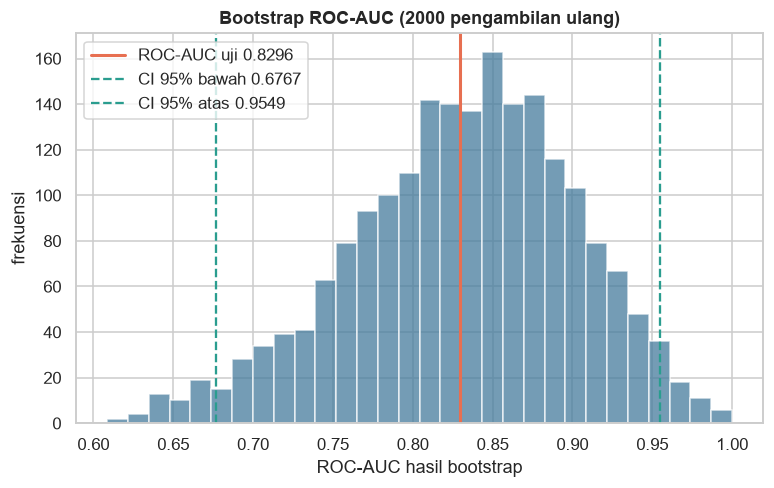

ROC-AUC 0.8296; CI95 bootstrap [0.6767, 0.9549]
File salah: 9 dari 40


,nim,n_files,n_class_0,n_class_1,n_benar,n_pred_1,n_salah,accuracy
0,24-068,6,3,3,4,5,2,0.6667
1,24-100,6,3,3,6,3,0,1.0000
2,24-119,6,3,3,6,3,0,1.0000
3,24-131,6,3,3,6,3,0,1.0000
4,24-145,6,3,3,4,3,2,0.6667
5,24-168,6,3,3,1,2,5,0.1667
6,24-169,4,3,1,4,1,0,1.0000


,file,nim,label_name,pred_label_name,proba_berisik
0,24-068_non-berisik_1.wav,24-068,non-berisik,berisik,0.7357
1,24-068_non-berisik_2.wav,24-068,non-berisik,berisik,0.5525
26,24-145_non-berisik_3.wav,24-145,non-berisik,berisik,0.5291
29,24-145_berisik_3.wav,24-145,berisik,non-berisik,0.3093
30,24-168_non-berisik_1.wav,24-168,non-berisik,berisik,0.8841
32,24-168_non-berisik_3.wav,24-168,non-berisik,berisik,0.8924
33,24-168_berisik_1.wav,24-168,berisik,non-berisik,0.0333
34,24-168_berisik_2.wav,24-168,berisik,non-berisik,0.2188
35,24-168_berisik_3.wav,24-168,berisik,non-berisik,0.3458


In [7]:
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_aucs = []
attempts = 0
n_samples = len(y_test)
while len(bootstrap_aucs) < BOOTSTRAP_N:
    attempts += 1
    if attempts > BOOTSTRAP_N * 100:
        raise RuntimeError("Bootstrap tidak konvergen; sampel satu kelas terlalu sering muncul.")
    sample_index = rng.integers(0, n_samples, n_samples)
    sampled_labels = y_test[sample_index]
    if np.unique(sampled_labels).size < 2:
        continue
    bootstrap_aucs.append(float(roc_auc_score(sampled_labels, proba_1[sample_index])))

bootstrap_aucs = np.asarray(bootstrap_aucs)
ci_low, ci_high = (float(value) for value in np.percentile(bootstrap_aucs, [2.5, 97.5]))

metrics_by_nim = (
    test_predictions.groupby("nim")
    .agg(
        n_files=("file", "size"),
        n_class_0=("label", lambda values: int((values == 0).sum())),
        n_class_1=("label", lambda values: int((values == 1).sum())),
        n_benar=("benar", "sum"),
        n_pred_1=("pred_label", "sum"),
    )
    .reset_index()
)
metrics_by_nim["n_salah"] = metrics_by_nim["n_files"] - metrics_by_nim["n_benar"]
metrics_by_nim["accuracy"] = (
    metrics_by_nim["n_benar"] / metrics_by_nim["n_files"]
).round(4)
metrics_by_nim = metrics_by_nim.sort_values("nim").reset_index(drop=True)
assert len(metrics_by_nim) == len(nims_test)
assert int(metrics_by_nim["n_files"].sum()) == len(y_test)
metrics_by_nim.to_csv(METRICS_BY_NIM_PATH, index=False)

errors = test_predictions.loc[~test_predictions["benar"]].copy()
errors.to_csv(ERRORS_PATH, index=False)
assert len(errors) == fn + fp, "Jumlah file salah tidak cocok dengan confusion matrix."

metrics.update(
    {
        "roc_auc_ci_low": ci_low,
        "roc_auc_ci_high": ci_high,
        "roc_auc_ci_level": 0.95,
        "n_bootstrap": int(len(bootstrap_aucs)),
        "bootstrap_attempts": int(attempts),
        "n_files_wrong": int(len(errors)),
        "accuracy_per_nim_mean": float(metrics_by_nim["accuracy"].mean()),
        "accuracy_per_nim_min": float(metrics_by_nim["accuracy"].min()),
        "accuracy_per_nim_max": float(metrics_by_nim["accuracy"].max()),
    }
)
METRICS_PATH.write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.hist(bootstrap_aucs, bins=30, color="#457b9d", alpha=0.75)
ax.axvline(roc_auc_value, color="#e76f51", linewidth=2, label=f"ROC-AUC uji {roc_auc_value:.4f}")
ax.axvline(ci_low, color="#2a9d8f", linestyle="--", linewidth=1.5, label=f"CI 95% bawah {ci_low:.4f}")
ax.axvline(ci_high, color="#2a9d8f", linestyle="--", linewidth=1.5, label=f"CI 95% atas {ci_high:.4f}")
ax.set_xlabel("ROC-AUC hasil bootstrap")
ax.set_ylabel("frekuensi")
ax.set_title(f"Bootstrap ROC-AUC ({len(bootstrap_aucs)} pengambilan ulang)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(TEST_FIGURE_DIR / "roc_auc_bootstrap.png")
plt.show()

print(f"ROC-AUC {roc_auc_value:.4f}; CI95 bootstrap [{ci_low:.4f}, {ci_high:.4f}]")
print(f"File salah: {len(errors)} dari {len(y_test)}")
display(metrics_by_nim)
if len(errors):
    display(
        errors[
            ["file", "nim", "label_name", "pred_label_name", "proba_berisik"]
        ].round(4)
    )
else:
    print("Tidak ada file yang salah prediksi pada data uji.")


## 6. Validasi akhir dan serah-terima Tahap 06

Validasi memastikan evaluasi ini independen, lengkap, dan dapat dipakai untuk laporan akhir tanpa perbaikan diam-diam.

### Checklist

1. Gerbang Tahap 04 lulus dan `holdout_tested_in_stage_04 = false`.
2. Model dan file `best_model.joblib` **tidak berubah** selama tahap ini (sidik jari memori dan hash file identik dengan saat dimuat).
3. Evaluasi memakai tepat 40 file dari 7 NIM test; NIM train tidak pernah muncul.
4. Probabilitas sah, threshold 0,50 konsisten dengan `predict()`, dan tidak ada NaN.
5. ROC-AUC, PR-AUC, accuracy, precision, recall, F1, confusion matrix, dan classification report saling konsisten dan berjumlah 40 file.
6. Syarat ROC-AUC ≥ 0,85 dinilai dari angka nyata dan statusnya ikut tersimpan apa adanya.
7. Confidence interval bootstrap (2.000 ulang) dan rincian per NIM tersimpan.
8. Seluruh file keluaran dan kelima gambar tersedia di `artifacts/test_results/`.
9. Tidak ada pelatihan, penalaan threshold, atau pemilihan fitur di tahap ini.


In [8]:
reloaded_model = joblib.load(MODEL_PATH)
in_memory_fingerprint = hashlib.sha256(pickle.dumps(saved_model)).hexdigest()
file_sha256_now = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

pred_from_csv = pd.read_csv(PREDICTIONS_PATH)
metrics_saved = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
report_saved = pd.read_csv(REPORT_METRICS_PATH, index_col=0)
cm_saved = pd.read_csv(CONFUSION_PATH, index_col=0)
metrics_by_nim_csv = pd.read_csv(METRICS_BY_NIM_PATH)
errors_csv = pd.read_csv(ERRORS_PATH)

required_metric_keys = {
    "roc_auc",
    "pr_auc",
    "accuracy",
    "precision_class_1",
    "recall_class_1",
    "f1_class_1",
    "confusion_matrix",
    "baseline_roc_auc",
    "pr_baseline_prevalence",
    "roc_auc_threshold",
    "roc_auc_meets_threshold",
    "kelayakan_status",
    "roc_auc_ci_low",
    "roc_auc_ci_high",
    "n_bootstrap",
    "nims_test",
    "n_files_test",
    "n_nim_test",
    "random_state",
}
required_result_files = [
    PREDICTIONS_PATH,
    METRICS_PATH,
    REPORT_METRICS_PATH,
    CONFUSION_PATH,
    METRICS_BY_NIM_PATH,
    ERRORS_PATH,
]

proba_from_csv = pred_from_csv[["proba_non_berisik", "proba_berisik"]].to_numpy(dtype=float)
checks = {
    "gate04_pass": (
        stage4_validation["status"] == "PASS"
        and stage4_validation["checks_passed"] == stage4_validation["checks_total"]
        and stage4_validation["holdout_tested_in_stage_04"] is False
    ),
    "konfigurasi_model_lengkap": {
        "model_name",
        "feature_columns",
        "holdout",
        "best_cv_roc_auc",
        "train_rows",
    }.issubset(model_config.keys()),
    "feature_columns_cocok": model_config["feature_columns"] == FEATURE_COLUMNS,
    "model_file_tidak_berubah": file_sha256_now == model_file_sha256_at_load,
    "model_memori_tidak_diubah": in_memory_fingerprint == model_fingerprint_at_load,
    "pipeline_struktur": list(reloaded_model.named_steps) == ["scaler", "select", "clf"],
    "evaluasi_hanya_40_file": len(pred_from_csv) == 40
    and pred_from_csv["file"].is_unique
    and set(pred_from_csv["split"]) == {"test"},
    "evaluasi_hanya_nim_test": set(pred_from_csv["nim"]).issubset(set(nims_test))
    and set(pred_from_csv["nim"]).isdisjoint(set(nims_train)),
    "n_nim_test_7": int(pred_from_csv["nim"].nunique()) == 7,
    "prediksi_tanpa_nan": not pred_from_csv.isna().any().any()
    and np.isfinite(proba_from_csv).all(),
    "probabilitas_sah": float(proba_from_csv.min()) >= 0.0
    and float(proba_from_csv.max()) <= 1.0
    and bool(np.allclose(proba_from_csv.sum(axis=1), 1.0)),
    "threshold_konsisten": bool(
        np.array_equal(
            pred_from_csv["pred_label"].to_numpy(dtype=int),
            (pred_from_csv["proba_berisik"].to_numpy(dtype=float) >= TEST_THRESHOLD).astype(int),
        )
    ),
    "label_prediksi_sah": set(pred_from_csv["pred_label"].unique()).issubset({0, 1}),
    "roc_auc_sah": 0.0 <= roc_auc_value <= 1.0 and np.isfinite(roc_auc_value),
    "pr_auc_sah": 0.0 <= pr_auc_value <= 1.0 and np.isfinite(pr_auc_value),
    "accuracy_sah": abs(accuracy_value - float((pred_label == y_test).mean())) < 1e-12,
    "confusion_40": tn + fp + fn + tp == 40
    and int(metrics_saved["confusion_matrix"]["tn"]) == tn
    and int(cm_saved.to_numpy().sum()) == 40,
    "classification_report_lengkap": {
        "non-berisik",
        "berisik",
        "accuracy",
    }.issubset(set(report_saved.index.astype(str))),
    "metrics_json_lengkap": required_metric_keys.issubset(metrics_saved.keys()),
    "status_085_konsisten": (
        metrics_saved["roc_auc_meets_threshold"] == (roc_auc_value >= ROC_AUC_THRESHOLD)
        and metrics_saved["kelayakan_status"]
        == ("LOLOS SYARAT AWAL" if roc_auc_value >= ROC_AUC_THRESHOLD else "DI BAWAH SYARAT AWAL")
    ),
    "baseline_05_tercatat": abs(float(metrics_saved["baseline_roc_auc"]) - 0.5) < 1e-12,
    "ci_bootstrap_sah": (
        float(metrics_saved["roc_auc_ci_low"]) < float(metrics_saved["roc_auc_ci_high"])
        and 0.0 <= float(metrics_saved["roc_auc_ci_low"])
        and float(metrics_saved["roc_auc_ci_high"]) <= 1.0
        and int(metrics_saved["n_bootstrap"]) == BOOTSTRAP_N
    ),
    "per_nim_7_lengkap": len(metrics_by_nim_csv) == 7
    and int(metrics_by_nim_csv["n_files"].sum()) == 40
    and sorted(metrics_by_nim_csv["nim"].astype(str)) == nims_test,
    "errors_konsisten": len(errors_csv) == fn + fp == int(metrics_saved["n_files_wrong"]),
    "holdout_tidak_dilatih": (
        int(model_config["train_rows"]) == 136
        and int(model_config["holdout"]["n_files_test"]) == 40
        and len(train_frame) == 136
    ),
    "random_state_tercatat": int(metrics_saved["random_state"]) == RANDOM_STATE,
    "test_results_lengkap": all(path.is_file() for path in required_result_files),
    "figures_tersimpan": all((TEST_FIGURE_DIR / name).is_file() for name in FIGURES_EXPECTED),
}

check_table = pd.DataFrame(
    {"pemeriksaan": list(checks.keys()), "lulus": list(checks.values())}
)
check_table["status"] = np.where(check_table["lulus"], "PASS", "FAIL")

if not all(checks.values()):
    display(check_table)
    raise ValueError("Validasi akhir Tahap 05 gagal.")

check_table.to_csv(ARTIFACT_DIR / "validation_checks.csv", index=False)

validation_summary = {
    "status": "PASS",
    "model_name": model_config["model_name"],
    "n_files_test": 40,
    "n_nim_test": 7,
    "roc_auc": roc_auc_value,
    "roc_auc_ci": [ci_low, ci_high],
    "pr_auc": pr_auc_value,
    "accuracy": accuracy_value,
    "precision_class_1": precision_value,
    "recall_class_1": recall_value,
    "f1_class_1": f1_value,
    "kelayakan_status": metrics["kelayakan_status"],
    "model_unchanged": True,
    "holdout_only": True,
    "checks_passed": int(check_table["lulus"].sum()),
    "checks_total": int(len(check_table)),
}
(ARTIFACT_DIR / "validation_summary.json").write_text(
    json.dumps(validation_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

validation_report_lines = [
    "# Laporan Validasi Tahap 05",
    "",
    "Status: **PASS**",
    "",
    "## Angka aktual",
    "",
    f"- File uji: 40 dari {len(nims_test)} NIM test",
    f"- ROC-AUC: {roc_auc_value:.4f} (CI95 bootstrap {ci_low:.4f} - {ci_high:.4f})",
    f"- PR-AUC: {pr_auc_value:.4f}",
    f"- Precision / recall / F1 kelas 1: {precision_value:.4f} / {recall_value:.4f} / {f1_value:.4f}",
    f"- Confusion TN/FP/FN/TP: {tn}/{fp}/{fn}/{tp}",
    f"- Status syarat 0,85: {metrics['kelayakan_status']}",
    f"- Pemeriksaan lulus: {check_table['lulus'].sum()}/{len(check_table)}",
    "",
    "## Catatan",
    "",
    "- Model tidak di-fit ulang; sidik jari memori dan hash file identik saat dimuat.",
    "- Metrik hanya memakai NIM test; NIM train tidak muncul.",
    "- Threshold keputusan tetap 0,50 dan tidak dituning pada data uji.",
]
(ARTIFACT_DIR / "validation_report.md").write_text(
    "\n".join(validation_report_lines) + "\n", encoding="utf-8"
)

display(check_table)
print("Validasi akhir Tahap 05: PASS")
print(f"Laporan: {ARTIFACT_DIR / 'validation_report.md'}")


,pemeriksaan,lulus,status
0,gate04_pass,True,PASS
1,konfigurasi_model_lengkap,True,PASS
2,feature_columns_cocok,True,PASS
3,model_file_tidak_berubah,True,PASS
4,model_memori_tidak_diubah,True,PASS
5,pipeline_struktur,True,PASS
6,evaluasi_hanya_40_file,True,PASS
7,evaluasi_hanya_nim_test,True,PASS
8,n_nim_test_7,True,PASS
9,prediksi_tanpa_nan,True,PASS


Validasi akhir Tahap 05: PASS
Laporan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\05_evaluation\validation_report.md


In [9]:
def md_table(frame, max_rows=None):
    view = frame if max_rows is None else frame.head(max_rows)
    columns = [str(column) for column in view.columns]
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in view.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                text = f"{value:.6g}"
            elif isinstance(value, (bool, np.bool_)):
                text = str(bool(value))
            else:
                text = str(value)
            values.append(text.replace("|", "\\|").replace("\n", " "))
        lines.append("| " + " | ".join(values) + " |")
    if len(frame) > len(view):
        lines.append("")
        lines.append(f"*Menampilkan {len(view)} dari {len(frame)} baris.*")
    return "\n".join(lines)


worst_nim_row = metrics_by_nim.loc[metrics_by_nim["accuracy"].idxmin()]
n_perfect_nim = int((metrics_by_nim["accuracy"] == 1.0).sum())
max_errors_nim = metrics_by_nim.loc[metrics_by_nim["n_salah"].idxmax()]
ci_includes_threshold = bool(ci_low <= ROC_AUC_THRESHOLD <= ci_high)
ci_note = (
    f"CI95 **memuat** {ROC_AUC_THRESHOLD:.2f}, sehingga kelayakan pada populasi "
    "tidak dapat dipastikan dari data uji ini saja."
    if ci_includes_threshold
    else f"CI95 **tidak memuat** {ROC_AUC_THRESHOLD:.2f}."
)

metrics_view = pd.DataFrame(
    {
        "metrik": [
            "ROC-AUC",
            "ROC-AUC CI 95% (bootstrap)",
            "PR-AUC",
            "accuracy",
            "precision (kelas 1)",
            "recall (kelas 1)",
            "F1 (kelas 1)",
            "accuracy per NIM (rata-rata)",
        ],
        "nilai": [
            f"{roc_auc_value:.4f}",
            f"[{ci_low:.4f}, {ci_high:.4f}]",
            f"{pr_auc_value:.4f}",
            f"{accuracy_value:.4f}",
            f"{precision_value:.4f}",
            f"{recall_value:.4f}",
            f"{f1_value:.4f}",
            f"{metrics['accuracy_per_nim_mean']:.4f}",
        ],
        "acuan": [
            "baseline 0,5000; syarat 0,85",
            "2.000 pengambilan ulang",
            f"baseline prevalensi {prevalence_value:.4f}",
            "kelas hampir seimbang",
            "kelas positif = berisik",
            "kelas positif = berisik",
            "precision dan recall",
            f"rentang {metrics['accuracy_per_nim_min']:.4f} - {metrics['accuracy_per_nim_max']:.4f}",
        ],
    }
)

cm_view = cm_frame.reset_index().rename(columns={"index": "aktual"})
report_view = report_frame.reset_index().rename(columns={"index": "kelas"})
errors_view = (
    errors[["file", "nim", "label_name", "pred_label_name", "proba_berisik"]]
    if len(errors)
    else pd.DataFrame(columns=["file", "nim", "label_name", "pred_label_name", "proba_berisik"])
)

report = f"""# 05 — Evaluation: Laporan Aktual

## Ringkasan

Model dari Tahap 04 diuji **satu kali** pada NIM hold-out yang dikunci; tidak ada pelatihan atau penalaan ulang di tahap ini.

- Model: **{model_config['model_name']}** (`{model_config['model_class']}`), threshold keputusan {TEST_THRESHOLD}.
- Data uji: **{len(y_test)} file** dari **{len(nims_test)} NIM test**: {", ".join(f"`{nim}`" for nim in nims_test)}.
- **ROC-AUC = {roc_auc_value:.4f}** dengan CI95 bootstrap [{ci_low:.4f}, {ci_high:.4f}] terhadap baseline 0,50 dan syarat kelayakan 0,85.
- Status syarat kelayakan awal: **{metrics['kelayakan_status']}**.
- PR-AUC = {pr_auc_value:.4f} (baseline prevalensi {prevalence_value:.4f}); accuracy = {accuracy_value:.4f}; F1 kelas berisik = {f1_value:.4f}.
- File salah prediksi: {len(errors)} dari {len(y_test)}.
- Pemeriksaan validasi: {check_table['lulus'].sum()}/{len(check_table)} PASS.

## Metrik hold-out

{md_table(metrics_view)}

Confusion matrix (threshold {TEST_THRESHOLD}):

{md_table(cm_view)}

Classification report:

{md_table(report_view)}

Keterangan baris: TN={tn}, FP={fp}, FN={fn}, TP={tp}. Kelas 1 = berisik adalah kelas positif.

## Rincian per NIM test

{md_table(metrics_by_nim)}

- NIM dengan accuracy sempurna: **{n_perfect_nim} dari {len(metrics_by_nim)}** ({", ".join(metrics_by_nim.loc[metrics_by_nim['accuracy'] == 1.0, 'nim'])}).
- Accuracy per NIM rata-rata {metrics['accuracy_per_nim_mean']:.4f}, terendah **{worst_nim_row['nim']} = {worst_nim_row['accuracy']:.4f}** ({int(worst_nim_row['n_salah'])} kesalahan dari {int(worst_nim_row['n_files'])} file).
- {int(max_errors_nim['n_salah'])} dari {len(errors)} kesalahan berasal dari satu NIM (`{max_errors_nim['nim']}`), sehingga hasil sangat dipengaruhi subjek/perangkat tersebut.

## File yang salah prediksi

{md_table(errors_view) if len(errors_view) else "Tidak ada file yang salah prediksi."}

File tetap dipertahankan; tidak ada yang dibuang karena dianggap sulit.

## Ketidakpastian

- ROC-AUC {roc_auc_value:.4f} memiliki CI95 bootstrap [{ci_low:.4f}, {ci_high:.4f}] dari {int(metrics['n_bootstrap'])} pengambilan ulang (random_state={RANDOM_STATE}).
- Dengan {len(nims_test)} NIM dan {len(y_test)} file, selisih satu dua file sudah menggeser metrik; angka hold-out adalah estimasi, bukan jaminan.
- {ci_note}

## Gambar

Seluruh gambar berada di `artifacts/test_results/figures/`:

- `roc_curve.png` — ROC-AUC {roc_auc_value:.4f} terhadap diagonal 0,50.
- `pr_curve.png` — PR-AUC {pr_auc_value:.4f} terhadap baseline prevalensi {prevalence_value:.4f}.
- `confusion_matrix.png` — heatmap TN/FP/FN/TP.
- `proba_distribution.png` — sebaran probabilitas berisik per kelas nyata dengan garis threshold {TEST_THRESHOLD}.
- `roc_auc_bootstrap.png` — sebaran ROC-AUC bootstrap beserta CI.

## Validasi akhir

Semua pemeriksaan lulus: **{check_table['lulus'].sum()}/{len(check_table)}**.

{md_table(check_table[['pemeriksaan', 'status']])}

## Batasan

- Hanya {len(nims_test)} NIM dan {len(y_test)} file uji; angka sedikit, ketidakpastian lebar.
- Label berasal dari protokol pengumpulan, bukan verifikasi audit kebenaran mutlak.
- Threshold {TEST_THRESHOLD} tidak dituning; menaikkan threshold menaikkan precision dan menurunkan recall.
- Probabilitas output belum terkalibrasi.
- Model terpilih memperoleh keuntungan tuning pada Tahap 04; hold-out ini adalah pengadilan pertama dan terakhir yang independen.
- Kelayakan awal ≠ layak produksi; batasan privasi dan perangkat/ruangan tetap berlaku.

## Kesimpulan dan keputusan untuk Tahap 06

1. Pakai `artifacts/best_model.joblib` dan `artifacts/04_modeling/model_config.json` apa adanya; jangan melatih atau menala ulang.
2. Fungsi `predict_audio(path)` harus meniru prapemrosesan Tahap 03 (mono 16 kHz, crop/pad 480.000 sampel, peak normalization, 12 fitur) lalu memakai pipeline ini.
3. Metrik hold-out yang dilaporkan di `artifacts/test_results/metrics.json` adalah angka resmi tahap ini.
4. `artifacts/LAPORAN.md` pada Tahap 06 memuat data aktual, fitur, model, metrik nyata, lokasi artefak, dan limitasi.

**Evaluation selesai dan tervalidasi. Metrik hold-out dilaporkan apa adanya.**
"""

(ARTIFACT_DIR / "evaluation_report.md").write_text(report, encoding="utf-8")

evaluation_summary = {
    "status": "PASS",
    "model_name": model_config["model_name"],
    "model_class": model_config["model_class"],
    "n_files_test": int(len(y_test)),
    "n_nim_test": int(len(nims_test)),
    "nims_test": nims_test,
    "class_counts_test": metrics["class_counts_test"],
    "test_threshold": TEST_THRESHOLD,
    "roc_auc": roc_auc_value,
    "roc_auc_ci_low": ci_low,
    "roc_auc_ci_high": ci_high,
    "pr_auc": pr_auc_value,
    "accuracy": accuracy_value,
    "precision_class_1": precision_value,
    "recall_class_1": recall_value,
    "f1_class_1": f1_value,
    "confusion_matrix": {"tn": tn, "fp": fp, "fn": fn, "tp": tp},
    "kelayakan_status": metrics["kelayakan_status"],
    "roc_auc_meets_threshold": metrics["roc_auc_meets_threshold"],
    "n_files_wrong": int(len(errors)),
    "checks_passed": int(check_table["lulus"].sum()),
    "checks_total": int(len(check_table)),
    "model_unchanged": True,
    "random_state": RANDOM_STATE,
}
(ARTIFACT_DIR / "evaluation_summary.json").write_text(
    json.dumps(evaluation_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"Laporan tahap: {ARTIFACT_DIR / 'evaluation_report.md'}")
display(Markdown(report))


Laporan tahap: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\05_evaluation\evaluation_report.md


# 05 — Evaluation: Laporan Aktual

## Ringkasan

Model dari Tahap 04 diuji **satu kali** pada NIM hold-out yang dikunci; tidak ada pelatihan atau penalaan ulang di tahap ini.

- Model: **Logistic Regression** (`LogisticRegression`), threshold keputusan 0.5.
- Data uji: **40 file** dari **7 NIM test**: `24-068`, `24-100`, `24-119`, `24-131`, `24-145`, `24-168`, `24-169`.
- **ROC-AUC = 0.8296** dengan CI95 bootstrap [0.6767, 0.9549] terhadap baseline 0,50 dan syarat kelayakan 0,85.
- Status syarat kelayakan awal: **DI BAWAH SYARAT AWAL**.
- PR-AUC = 0.8481 (baseline prevalensi 0.4750); accuracy = 0.7750; F1 kelas berisik = 0.7692.
- File salah prediksi: 9 dari 40.
- Pemeriksaan validasi: 28/28 PASS.

## Metrik hold-out

| metrik | nilai | acuan |
|---|---|---|
| ROC-AUC | 0.8296 | baseline 0,5000; syarat 0,85 |
| ROC-AUC CI 95% (bootstrap) | [0.6767, 0.9549] | 2.000 pengambilan ulang |
| PR-AUC | 0.8481 | baseline prevalensi 0.4750 |
| accuracy | 0.7750 | kelas hampir seimbang |
| precision (kelas 1) | 0.7500 | kelas positif = berisik |
| recall (kelas 1) | 0.7895 | kelas positif = berisik |
| F1 (kelas 1) | 0.7692 | precision dan recall |
| accuracy per NIM (rata-rata) | 0.7857 | rentang 0.1667 - 1.0000 |

Confusion matrix (threshold 0.5):

| aktual | pred_non_berisik | pred_berisik |
|---|---|---|
| actual_non_berisik | 16 | 5 |
| actual_berisik | 4 | 15 |

Classification report:

| kelas | precision | recall | f1-score | support |
|---|---|---|---|---|
| non-berisik | 0.8 | 0.7619 | 0.7805 | 21 |
| berisik | 0.75 | 0.7895 | 0.7692 | 19 |
| accuracy | 0.775 | 0.775 | 0.775 | 0.775 |
| macro avg | 0.775 | 0.7757 | 0.7749 | 40 |
| weighted avg | 0.7762 | 0.775 | 0.7751 | 40 |

Keterangan baris: TN=16, FP=5, FN=4, TP=15. Kelas 1 = berisik adalah kelas positif.

## Rincian per NIM test

| nim | n_files | n_class_0 | n_class_1 | n_benar | n_pred_1 | n_salah | accuracy |
|---|---|---|---|---|---|---|---|
| 24-068 | 6 | 3 | 3 | 4 | 5 | 2 | 0.6667 |
| 24-100 | 6 | 3 | 3 | 6 | 3 | 0 | 1 |
| 24-119 | 6 | 3 | 3 | 6 | 3 | 0 | 1 |
| 24-131 | 6 | 3 | 3 | 6 | 3 | 0 | 1 |
| 24-145 | 6 | 3 | 3 | 4 | 3 | 2 | 0.6667 |
| 24-168 | 6 | 3 | 3 | 1 | 2 | 5 | 0.1667 |
| 24-169 | 4 | 3 | 1 | 4 | 1 | 0 | 1 |

- NIM dengan accuracy sempurna: **4 dari 7** (24-100, 24-119, 24-131, 24-169).
- Accuracy per NIM rata-rata 0.7857, terendah **24-168 = 0.1667** (5 kesalahan dari 6 file).
- 5 dari 9 kesalahan berasal dari satu NIM (`24-168`), sehingga hasil sangat dipengaruhi subjek/perangkat tersebut.

## File yang salah prediksi

| file | nim | label_name | pred_label_name | proba_berisik |
|---|---|---|---|---|
| 24-068_non-berisik_1.wav | 24-068 | non-berisik | berisik | 0.735735 |
| 24-068_non-berisik_2.wav | 24-068 | non-berisik | berisik | 0.552531 |
| 24-145_non-berisik_3.wav | 24-145 | non-berisik | berisik | 0.52914 |
| 24-145_berisik_3.wav | 24-145 | berisik | non-berisik | 0.309293 |
| 24-168_non-berisik_1.wav | 24-168 | non-berisik | berisik | 0.884149 |
| 24-168_non-berisik_3.wav | 24-168 | non-berisik | berisik | 0.892399 |
| 24-168_berisik_1.wav | 24-168 | berisik | non-berisik | 0.0333481 |
| 24-168_berisik_2.wav | 24-168 | berisik | non-berisik | 0.218829 |
| 24-168_berisik_3.wav | 24-168 | berisik | non-berisik | 0.345816 |

File tetap dipertahankan; tidak ada yang dibuang karena dianggap sulit.

## Ketidakpastian

- ROC-AUC 0.8296 memiliki CI95 bootstrap [0.6767, 0.9549] dari 2000 pengambilan ulang (random_state=42).
- Dengan 7 NIM dan 40 file, selisih satu dua file sudah menggeser metrik; angka hold-out adalah estimasi, bukan jaminan.
- CI95 **memuat** 0.85, sehingga kelayakan pada populasi tidak dapat dipastikan dari data uji ini saja.

## Gambar

Seluruh gambar berada di `artifacts/test_results/figures/`:

- `roc_curve.png` — ROC-AUC 0.8296 terhadap diagonal 0,50.
- `pr_curve.png` — PR-AUC 0.8481 terhadap baseline prevalensi 0.4750.
- `confusion_matrix.png` — heatmap TN/FP/FN/TP.
- `proba_distribution.png` — sebaran probabilitas berisik per kelas nyata dengan garis threshold 0.5.
- `roc_auc_bootstrap.png` — sebaran ROC-AUC bootstrap beserta CI.

## Validasi akhir

Semua pemeriksaan lulus: **28/28**.

| pemeriksaan | status |
|---|---|
| gate04_pass | PASS |
| konfigurasi_model_lengkap | PASS |
| feature_columns_cocok | PASS |
| model_file_tidak_berubah | PASS |
| model_memori_tidak_diubah | PASS |
| pipeline_struktur | PASS |
| evaluasi_hanya_40_file | PASS |
| evaluasi_hanya_nim_test | PASS |
| n_nim_test_7 | PASS |
| prediksi_tanpa_nan | PASS |
| probabilitas_sah | PASS |
| threshold_konsisten | PASS |
| label_prediksi_sah | PASS |
| roc_auc_sah | PASS |
| pr_auc_sah | PASS |
| accuracy_sah | PASS |
| confusion_40 | PASS |
| classification_report_lengkap | PASS |
| metrics_json_lengkap | PASS |
| status_085_konsisten | PASS |
| baseline_05_tercatat | PASS |
| ci_bootstrap_sah | PASS |
| per_nim_7_lengkap | PASS |
| errors_konsisten | PASS |
| holdout_tidak_dilatih | PASS |
| random_state_tercatat | PASS |
| test_results_lengkap | PASS |
| figures_tersimpan | PASS |

## Batasan

- Hanya 7 NIM dan 40 file uji; angka sedikit, ketidakpastian lebar.
- Label berasal dari protokol pengumpulan, bukan verifikasi audit kebenaran mutlak.
- Threshold 0.5 tidak dituning; menaikkan threshold menaikkan precision dan menurunkan recall.
- Probabilitas output belum terkalibrasi.
- Model terpilih memperoleh keuntungan tuning pada Tahap 04; hold-out ini adalah pengadilan pertama dan terakhir yang independen.
- Kelayakan awal ≠ layak produksi; batasan privasi dan perangkat/ruangan tetap berlaku.

## Kesimpulan dan keputusan untuk Tahap 06

1. Pakai `artifacts/best_model.joblib` dan `artifacts/04_modeling/model_config.json` apa adanya; jangan melatih atau menala ulang.
2. Fungsi `predict_audio(path)` harus meniru prapemrosesan Tahap 03 (mono 16 kHz, crop/pad 480.000 sampel, peak normalization, 12 fitur) lalu memakai pipeline ini.
3. Metrik hold-out yang dilaporkan di `artifacts/test_results/metrics.json` adalah angka resmi tahap ini.
4. `artifacts/LAPORAN.md` pada Tahap 06 memuat data aktual, fitur, model, metrik nyata, lokasi artefak, dan limitasi.

**Evaluation selesai dan tervalidasi. Metrik hold-out dilaporkan apa adanya.**


## Kesimpulan dan keputusan untuk tahap 06

1. **Evaluasi independen:** model dimuat tanpa di-fit ulang (sidik jari memori dan hash file identik sejak dimuat), evaluasi memakai **tepat 40 file dari 7 NIM test** (`24-068`, `24-100`, `24-119`, `24-131`, `24-145`, `24-168`, `24-169`), threshold 0,50 tidak dituning, dan seluruh pemeriksaan **28/28 PASS**.
2. **Hasil utama:** **ROC-AUC = 0,8296** terhadap baseline 0,50 — **DI BAWAH SYARAT AWAL 0,85**; CI95 bootstrap [0,6767, 0,9549] **memuat 0,85**, sehingga kelayakan pada populasi tidak dapat dipastikan dari 40 file ini. Dilaporkan apa adanya, tidak disesuaikan.
3. **Metrik lain:** PR-AUC 0,8481 (baseline prevalensi 0,475), accuracy 0,7750, precision berisik 0,7500, recall berisik 0,7895, F1 berisik 0,7692; confusion **TN 16, FP 5, FN 4, TP 15** (9 file salah dari 40).
4. **Sebaran kesalahan:** 4 NIM sempurna (`24-100`, `24-119`, `24-131`, `24-169`), `24-068` dan `24-145` benar 4/6, sedangkan `24-168` hanya benar 1/6 — 5 dari 9 kesalahan menumpuk pada satu subjek; hal ini menunjukkan sensitivitas subjek/perangkat dan diperiksa kembali di `errors.csv`.
5. **Artefak resmi:** `artifacts/test_results/` berisi `metrics.json`, `test_predictions.csv`, `classification_report.csv`, `confusion_matrix.csv`, `metrics_by_nim.csv`, `errors.csv`, dan 5 gambar; laporan tahap di `artifacts/05_evaluation/evaluation_report.md`.
6. **Tahap 06:** memakai `best_model.joblib` apa adanya (tanpa training/penalaan), membangun `predict_audio(path)` dengan prapemrosesan identik Tahap 03, mendemokan pada file asli, lalu menulis `artifacts/LAPORAN.md` yang memuat angka-angka di atas **beserta status di bawah syarat 0,85 dan seluruh limitasinya**.

**Evaluation selesai dan tervalidasi. Metrik hold-out dilaporkan apa adanya.**
